In [1]:
# ============================================================
# Celda 1: Importación de librerías y configuración inicial
# ============================================================
# En esta celda se importan las librerías necesarias para la etapa
# de feature engineering y normalización de variables.
# También se definen las rutas de los datasets seleccionados.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.preprocessing import StandardScaler, MinMaxScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

DATASET_TOP_GLOBAL = "dataset-phishing-selected-top25.csv"

DATASET_BALANCEADO = (
    "dataset-phishing-balanced-url10-html10-service5.csv"
)

TARGET_COL = "status"

COLOR_PRIMARIO = "#3A6EA5"
COLOR_SECUNDARIO = "#5DADE2"
COLOR_TERCIARIO = "#95A5A6"

sns.set_theme(style="whitegrid")

In [2]:
# ============================================================
# Celda 2: Carga de datasets seleccionados
# ============================================================
# En esta celda se cargan los dos datasets generados en el notebook
# de selección de características:
#
# 1. Dataset Top N global
# 2. Dataset balanceado por grupos
#
# Ambos serán preparados para entrenamiento final.

df_top = pd.read_csv(DATASET_TOP_GLOBAL)

df_balanceado = pd.read_csv(DATASET_BALANCEADO)

print("Dataset Top Global:", df_top.shape)
print("Dataset Balanceado:", df_balanceado.shape)

print("\nPrimeras filas Top Global:")
display(df_top.head())

print("\nPrimeras filas Balanceado:")
display(df_balanceado.head())

Dataset Top Global: (11429, 27)
Dataset Balanceado: (11429, 27)

Primeras filas Top Global:


,url,google_index,domain_age,nb_hyperlinks,nb_www,phish_hints,safe_anchor,longest_word_path,ratio_digits_url,ratio_intHyperlinks,longest_words_raw,domain_in_title,length_words_raw,nb_dots,domain_registration_length,ratio_extRedirection,nb_hyphens,char_repeat,length_hostname,nb_slash,ratio_extHyperlinks,links_in_tags,avg_word_path,domain_with_copyright,ip,ratio_extMedia,status
0,http://www.crestonwood.com/router.php,1,-1,17,1,0,0.0,6,0.000000,0.529412,11,0,4,3,45,0.875000,0,4,19,3,0.470588,80.000000,4.500000,1,0,0.000000,0
1,http://shadetreetechnology.com/V4/validation/a...,1,5767,30,0,0,100.0,32,0.220779,0.966667,32,1,4,1,77,0.000000,0,4,23,5,0.033333,100.000000,14.666667,0,1,20.000000,1
2,https://support-appleld.com.secureupdate.duila...,1,4004,4,0,0,100.0,17,0.150794,1.000000,17,1,12,4,14,0.000000,1,2,50,5,0.000000,100.000000,8.142857,0,1,0.000000,1
3,http://rgipt.ac.in,0,-1,149,0,0,62.5,0,0.000000,0.973154,5,1,1,2,62,0.250000,0,0,11,2,0.026846,100.000000,0.000000,0,0,3.571429,0
4,http://www.iracing.com/tracks/gateway-motorspo...,0,8175,102,1,0,0.0,11,0.000000,0.470588,11,0,6,2,224,0.537037,2,3,15,5,0.529412,76.470588,7.000000,1,0,100.000000,0



Primeras filas Balanceado:


,url,nb_www,phish_hints,longest_word_path,ratio_digits_url,longest_words_raw,length_words_raw,nb_dots,nb_hyphens,char_repeat,length_hostname,nb_hyperlinks,safe_anchor,ratio_intHyperlinks,domain_in_title,ratio_extRedirection,ratio_extHyperlinks,links_in_tags,domain_with_copyright,ratio_extMedia,ratio_extErrors,google_index,domain_age,domain_registration_length,dns_record,whois_registered_domain,status
0,http://www.crestonwood.com/router.php,1,0,6,0.000000,11,4,3,0,4,19,17,0.0,0.529412,0,0.875000,0.470588,80.000000,1,0.000000,0.500000,1,-1,45,1,0,0
1,http://shadetreetechnology.com/V4/validation/a...,0,0,32,0.220779,32,4,1,0,4,23,30,100.0,0.966667,1,0.000000,0.033333,100.000000,0,20.000000,0.000000,1,5767,77,0,0,1
2,https://support-appleld.com.secureupdate.duila...,0,0,17,0.150794,17,12,4,1,2,50,4,100.0,1.000000,1,0.000000,0.000000,100.000000,0,0.000000,0.000000,1,4004,14,0,0,1
3,http://rgipt.ac.in,0,0,0,0.000000,5,1,2,0,0,11,149,62.5,0.973154,1,0.250000,0.026846,100.000000,0,3.571429,0.250000,0,-1,62,0,0,0
4,http://www.iracing.com/tracks/gateway-motorspo...,1,0,11,0.000000,11,6,2,2,3,15,102,0.0,0.470588,0,0.537037,0.529412,76.470588,1,100.000000,0.018519,0,8175,224,0,0,0


In [3]:
# ============================================================
# Celda 3: Separación de variables predictoras y objetivo
# ============================================================
# En esta celda se separan las variables predictoras y la variable
# objetivo para ambos datasets.

# =========================
# Dataset Top Global
# =========================

X_top = df_top.drop(columns=["url", TARGET_COL], errors="ignore")
y_top = df_top[TARGET_COL]

# =========================
# Dataset Balanceado
# =========================

X_balanceado = df_balanceado.drop(
    columns=["url", TARGET_COL],
    errors="ignore"
)

y_balanceado = df_balanceado[TARGET_COL]

print("Top Global:", X_top.shape)
print("Balanceado:", X_balanceado.shape)

Top Global: (11429, 25)
Balanceado: (11429, 25)


In [4]:
# ============================================================
# Celda 4: Estandarización semántica de variables binarias
# ============================================================
# En esta celda se ajusta la interpretación de algunas variables binarias
# para que sigan una lógica más clara:
#
# 1 = presencia / condición favorable
# 0 = ausencia / condición no favorable
#
# Según el código original del autor, algunas variables están codificadas
# de forma inversa. Por ejemplo:
#
# google_index:
# 0 = indexado en Google
# 1 = no indexado
#
# dns_record:
# 0 = tiene registro DNS
# 1 = no tiene registro DNS
#
# whois_registered_domain:
# 0 = dominio reconocido por WHOIS
# 1 = dominio no reconocido
#
# domain_in_title:
# 0 = dominio aparece en el título
# 1 = dominio no aparece en el título
#
# domain_with_copyright:
# 0 = dominio aparece junto a copyright
# 1 = no aparece
#
# Estas variables se invierten para hacerlas más interpretables.

def invertir_binarias_semanticas(X):
    X = X.copy()

    columnas_a_invertir = [
        "google_index",
        "dns_record",
        "whois_registered_domain",
        "domain_in_title",
        "domain_with_copyright"
    ]

    columnas_presentes = [
        col for col in columnas_a_invertir
        if col in X.columns
    ]

    print("Columnas binarias invertidas:")
    print(columnas_presentes)

    for col in columnas_presentes:
        X[col] = X[col].map({
            0: 1,
            1: 0
        })

    return X


X_top = invertir_binarias_semanticas(X_top)

X_balanceado = invertir_binarias_semanticas(X_balanceado)

print("\nEstandarización semántica aplicada correctamente.")

print("\nValores únicos después de la transformación - Top Global:")
display(X_top[
    [col for col in [
        "google_index",
        "dns_record",
        "whois_registered_domain",
        "domain_in_title",
        "domain_with_copyright"
    ] if col in X_top.columns]
].nunique())

print("\nValores únicos después de la transformación - Balanceado:")
display(X_balanceado[
    [col for col in [
        "google_index",
        "dns_record",
        "whois_registered_domain",
        "domain_in_title",
        "domain_with_copyright"
    ] if col in X_balanceado.columns]
].nunique())

Columnas binarias invertidas:
['google_index', 'domain_in_title', 'domain_with_copyright']
Columnas binarias invertidas:
['google_index', 'dns_record', 'whois_registered_domain', 'domain_in_title', 'domain_with_copyright']

Estandarización semántica aplicada correctamente.

Valores únicos después de la transformación - Top Global:


google_index             2
domain_in_title          2
domain_with_copyright    2
dtype: int64


Valores únicos después de la transformación - Balanceado:


google_index               2
dns_record                 2
whois_registered_domain    2
domain_in_title            2
domain_with_copyright      2
dtype: int64

In [5]:
# ============================================================
# Celda 5: Análisis estadístico previo a la normalización
# ============================================================
# En esta celda se revisan estadísticas básicas de las variables
# antes del escalado.
#
# Esto permite identificar diferencias grandes de magnitud entre
# características, lo cual puede afectar modelos de Deep Learning.

print("===== TOP GLOBAL =====")
display(X_top.describe().T)

print("\n===== DATASET BALANCEADO =====")
display(X_balanceado.describe().T)

===== TOP GLOBAL =====


,count,mean,std,min,25%,50%,75%,max
google_index,11429.0,0.466095,0.498871,0.0,0.000000,0.000000,1.000000,1.000000
domain_age,11429.0,4062.407997,3107.886682,-12.0,972.000000,3993.000000,7027.000000,12874.000000
nb_hyperlinks,11429.0,87.195555,166.764400,0.0,9.000000,34.000000,101.000000,4659.000000
nb_www,11429.0,0.448508,0.501917,0.0,0.000000,0.000000,1.000000,2.000000
phish_hints,11429.0,0.327763,0.842632,0.0,0.000000,0.000000,0.000000,10.000000
safe_anchor,11429.0,37.064977,39.074932,0.0,0.000000,23.255814,75.000000,100.000000
longest_word_path,11429.0,10.561904,23.078854,0.0,0.000000,7.000000,11.000000,829.000000
ratio_digits_url,11429.0,0.053135,0.089366,0.0,0.000000,0.000000,0.079365,0.723881
ratio_intHyperlinks,11429.0,0.602493,0.376471,0.0,0.225806,0.743590,0.944785,1.000000
longest_words_raw,11429.0,15.394435,22.084530,2.0,9.000000,11.000000,16.000000,829.000000



===== DATASET BALANCEADO =====


,count,mean,std,min,25%,50%,75%,max
nb_www,11429.0,0.448508,0.501917,0.0,0.000000,0.000000,1.000000,2.000000
phish_hints,11429.0,0.327763,0.842632,0.0,0.000000,0.000000,0.000000,10.000000
longest_word_path,11429.0,10.561904,23.078854,0.0,0.000000,7.000000,11.000000,829.000000
ratio_digits_url,11429.0,0.053135,0.089366,0.0,0.000000,0.000000,0.079365,0.723881
longest_words_raw,11429.0,15.394435,22.084530,2.0,9.000000,11.000000,16.000000,829.000000
length_words_raw,11429.0,6.232654,5.572574,1.0,2.000000,5.000000,8.000000,106.000000
nb_dots,11429.0,2.480619,1.369672,1.0,2.000000,2.000000,3.000000,24.000000
nb_hyphens,11429.0,0.997638,2.087157,0.0,0.000000,0.000000,1.000000,43.000000
char_repeat,11429.0,2.927640,4.769110,0.0,1.000000,3.000000,4.000000,146.000000
length_hostname,11429.0,21.089859,10.777545,4.0,15.000000,19.000000,24.000000,214.000000


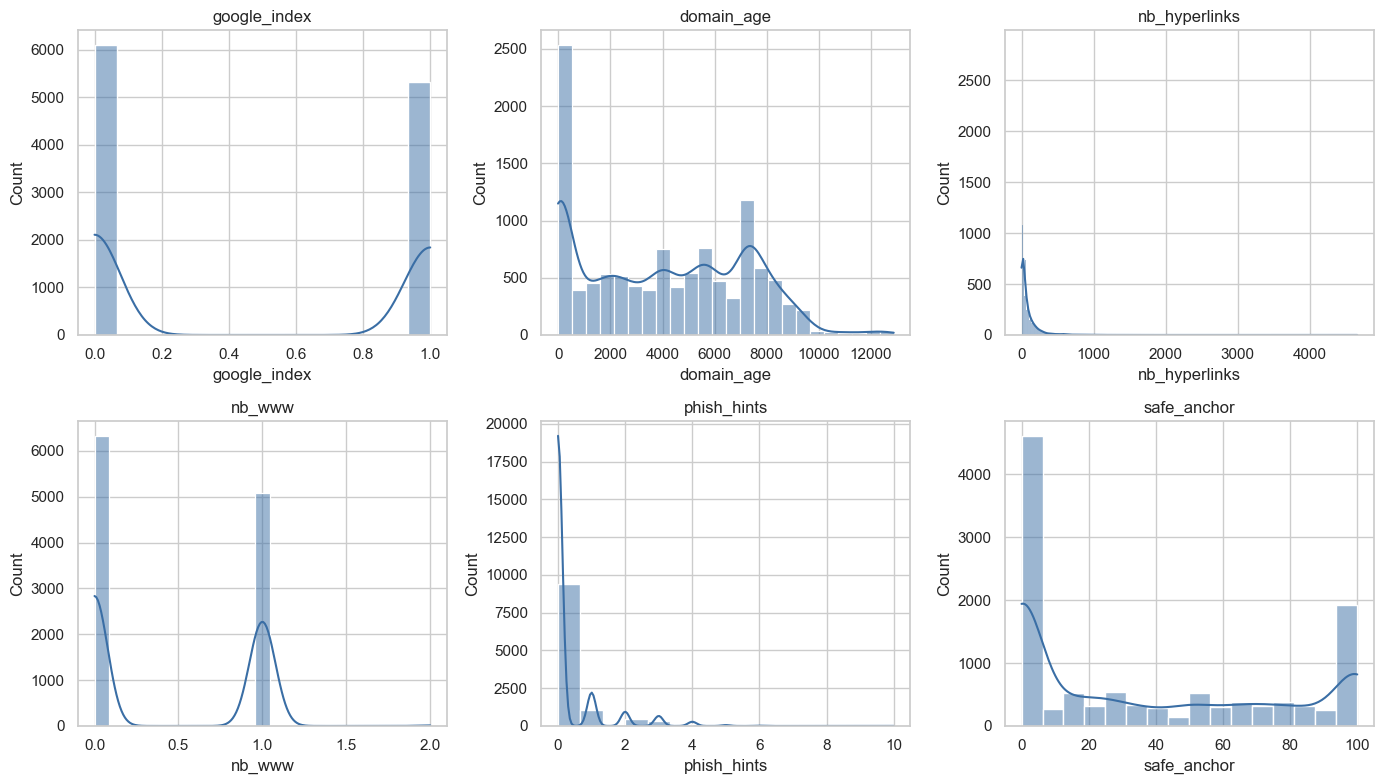

In [6]:
# ============================================================
# Celda 6: Distribución de variables antes de normalizar
# ============================================================
# En esta celda se visualizan algunas variables numéricas antes
# del escalado para observar sus distribuciones originales.

sample_features = X_top.columns[:6]

plt.figure(figsize=(14, 8))

for i, col in enumerate(sample_features, 1):

    plt.subplot(2, 3, i)

    sns.histplot(
        X_top[col],
        kde=True,
        color=COLOR_PRIMARIO
    )

    plt.title(col)

plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# Celda 7: Normalización selectiva con StandardScaler
# ============================================================
# En esta celda se normalizan únicamente las variables continuas.
#
# Las variables binarias y discretas pequeñas se mantienen sin escalar para:
# - conservar interpretabilidad,
# - evitar distorsión semántica,
# - mantener coherencia lógica.
#
# Nota:
# nb_www se mantiene sin escalar porque el autor la define como conteo
# de apariciones de "www" en los tokens de la URL. No se transforma a binaria.

# ============================================================
# Función para separar variables discretas pequeñas y continuas
# ============================================================

def separar_variables(df, umbral_discretas=3):

    discretas = []
    continuas = []

    for col in df.columns:

        valores_unicos = sorted(df[col].dropna().unique())

        if len(valores_unicos) <= umbral_discretas:
            discretas.append(col)
        else:
            continuas.append(col)

    return discretas, continuas


# =========================
# TOP GLOBAL
# =========================

discretas_top, continuas_top = separar_variables(
    X_top,
    umbral_discretas=3
)

print("Variables discretas/binarias sin escalar - Top Global:")
print(discretas_top)

print("\nVariables continuas escaladas - Top Global:")
print(continuas_top)

scaler_top = StandardScaler()

X_top_scaled = X_top.copy()

X_top_scaled[continuas_top] = scaler_top.fit_transform(
    X_top[continuas_top]
)


# =========================
# DATASET BALANCEADO
# =========================

discretas_balanceado, continuas_balanceado = separar_variables(
    X_balanceado,
    umbral_discretas=3
)

print("\nVariables discretas/binarias sin escalar - Balanceado:")
print(discretas_balanceado)

print("\nVariables continuas escaladas - Balanceado:")
print(continuas_balanceado)

scaler_balanceado = StandardScaler()

X_balanceado_scaled = X_balanceado.copy()

X_balanceado_scaled[continuas_balanceado] = scaler_balanceado.fit_transform(
    X_balanceado[continuas_balanceado]
)


print("\nNormalización selectiva aplicada correctamente.")

print("\nTop Global:")
display(X_top_scaled.head())

print("\nBalanceado:")
display(X_balanceado_scaled.head())

print("\nResumen:")
print("Top Global -> sin escalar:", len(discretas_top), "| escaladas:", len(continuas_top))
print("Balanceado -> sin escalar:", len(discretas_balanceado), "| escaladas:", len(continuas_balanceado))

Variables discretas/binarias sin escalar - Top Global:
['google_index', 'nb_www', 'domain_in_title', 'domain_with_copyright', 'ip']

Variables continuas escaladas - Top Global:
['domain_age', 'nb_hyperlinks', 'phish_hints', 'safe_anchor', 'longest_word_path', 'ratio_digits_url', 'ratio_intHyperlinks', 'longest_words_raw', 'length_words_raw', 'nb_dots', 'domain_registration_length', 'ratio_extRedirection', 'nb_hyphens', 'char_repeat', 'length_hostname', 'nb_slash', 'ratio_extHyperlinks', 'links_in_tags', 'avg_word_path', 'ratio_extMedia']

Variables discretas/binarias sin escalar - Balanceado:
['nb_www', 'domain_in_title', 'domain_with_copyright', 'google_index', 'dns_record', 'whois_registered_domain']

Variables continuas escaladas - Balanceado:
['phish_hints', 'longest_word_path', 'ratio_digits_url', 'longest_words_raw', 'length_words_raw', 'nb_dots', 'nb_hyphens', 'char_repeat', 'length_hostname', 'nb_hyperlinks', 'safe_anchor', 'ratio_intHyperlinks', 'ratio_extRedirection', 'ratio_

,google_index,domain_age,nb_hyperlinks,nb_www,phish_hints,safe_anchor,longest_word_path,ratio_digits_url,ratio_intHyperlinks,longest_words_raw,domain_in_title,length_words_raw,nb_dots,domain_registration_length,ratio_extRedirection,nb_hyphens,char_repeat,length_hostname,nb_slash,ratio_extHyperlinks,links_in_tags,avg_word_path,domain_with_copyright,ip,ratio_extMedia
0,0,-1.307508,-0.420945,1,-0.388992,-0.948603,-0.197675,-0.594606,-0.194131,-0.198991,1,-0.400668,0.379217,-0.549305,2.687599,-0.478010,0.224865,-0.193917,-0.685076,0.606135,0.674784,-0.082904,0,0,-0.605252
1,0,0.548497,-0.342987,0,-0.388992,1.610694,0.928947,1.875996,0.967376,0.751942,0,-0.400668,-1.081050,-0.510030,-0.596479,-0.478010,0.224865,0.177241,0.377519,-0.760630,1.156476,1.339596,1,1,-0.084187
2,0,-0.018794,-0.498903,0,-0.388992,1.610694,0.278973,1.092832,1.055922,0.072704,0,1.034997,1.109351,-0.587353,-0.596479,0.001132,-0.194519,2.682560,0.377519,-0.864823,1.156476,0.426797,1,1,-0.605252
3,1,-1.307508,0.370626,0,-0.388992,0.650958,-0.457664,-0.594606,0.984610,-0.470686,0,-0.939042,-0.350916,-0.528440,0.341829,-0.478010,-0.613902,-0.936234,-1.216374,-0.780909,1.156476,-0.712535,1,0,-0.512205
4,1,1.323334,0.088778,1,-0.388992,-0.948603,0.018983,-0.594606,-0.350388,-0.198991,1,-0.041752,-0.350916,-0.329610,1.419146,0.480274,0.015173,-0.565075,0.377519,0.790005,0.589780,0.266891,0,0,2.000075



Balanceado:


,nb_www,phish_hints,longest_word_path,ratio_digits_url,longest_words_raw,length_words_raw,nb_dots,nb_hyphens,char_repeat,length_hostname,nb_hyperlinks,safe_anchor,ratio_intHyperlinks,domain_in_title,ratio_extRedirection,ratio_extHyperlinks,links_in_tags,domain_with_copyright,ratio_extMedia,ratio_extErrors,google_index,domain_age,domain_registration_length,dns_record,whois_registered_domain
0,1,-0.388992,-0.197675,-0.594606,-0.198991,-0.400668,0.379217,-0.478010,0.224865,-0.193917,-0.420945,-0.948603,-0.194131,1,2.687599,0.606135,0.674784,0,-0.605252,2.800926,0,-1.307508,-0.549305,0,1
1,0,-0.388992,0.928947,1.875996,0.751942,-0.400668,-1.081050,-0.478010,0.224865,0.177241,-0.342987,1.610694,0.967376,0,-0.596479,-0.760630,1.156476,1,-0.084187,-0.399943,0,0.548497,-0.510030,1,1
2,0,-0.388992,0.278973,1.092832,0.072704,1.034997,1.109351,0.001132,-0.194519,2.682560,-0.498903,1.610694,1.055922,0,-0.596479,-0.864823,1.156476,1,-0.605252,-0.399943,0,-0.018794,-0.587353,1,1
3,0,-0.388992,-0.457664,-0.594606,-0.470686,-0.939042,-0.350916,-0.478010,-0.613902,-0.936234,0.370626,0.650958,0.984610,0,0.341829,-0.780909,1.156476,1,-0.512205,1.200492,1,-1.307508,-0.528440,1,1
4,1,-0.388992,0.018983,-0.594606,-0.198991,-0.041752,-0.350916,0.480274,0.015173,-0.565075,0.088778,-0.948603,-0.350388,1,1.419146,0.790005,0.589780,0,2.000075,-0.281392,1,1.323334,-0.329610,1,1



Resumen:
Top Global -> sin escalar: 5 | escaladas: 20
Balanceado -> sin escalar: 6 | escaladas: 19


In [8]:
# ============================================================
# Celda 8: Verificación posterior a la normalización
# ============================================================
# En esta celda se revisa que las variables continuas hayan sido
# correctamente escaladas y que las variables discretas/binarias
# se mantengan en su escala original.

print("===== TOP GLOBAL NORMALIZADO =====")
display(X_top_scaled.describe().T)

print("\n===== BALANCEADO NORMALIZADO =====")
display(X_balanceado_scaled.describe().T)

===== TOP GLOBAL NORMALIZADO =====


,count,mean,std,min,25%,50%,75%,max
google_index,11429.0,4.660950e-01,0.498871,0.000000,0.000000,0.000000,1.000000,1.000000
domain_age,11429.0,-1.056893e-17,1.000044,-1.311047,-0.994420,-0.022334,0.953935,2.835360
nb_hyperlinks,11429.0,2.953083e-17,1.000044,-0.522890,-0.468919,-0.319000,0.082782,27.415950
nb_www,11429.0,4.485082e-01,0.501917,0.000000,0.000000,0.000000,1.000000,2.000000
phish_hints,11429.0,7.273908e-17,1.000044,-0.388992,-0.388992,-0.388992,-0.388992,11.479109
safe_anchor,11429.0,-9.574204e-17,1.000044,-0.948603,-0.948603,-0.353418,0.970870,1.610694
longest_word_path,11429.0,3.450444e-17,1.000044,-0.457664,-0.457664,-0.154343,0.018983,35.464236
ratio_digits_url,11429.0,-3.636954e-17,1.000044,-0.594606,-0.594606,-0.594606,0.293519,7.505889
ratio_intHyperlinks,11429.0,-1.053784e-16,1.000044,-1.600440,-1.000616,0.374803,0.909251,1.055922
longest_words_raw,11429.0,1.336658e-17,1.000044,-0.606534,-0.289556,-0.198991,0.027422,36.842132



===== BALANCEADO NORMALIZADO =====


,count,mean,std,min,25%,50%,75%,max
nb_www,11429.0,4.485082e-01,0.501917,0.000000,0.000000,0.000000,1.000000,2.000000
phish_hints,11429.0,7.273908e-17,1.000044,-0.388992,-0.388992,-0.388992,-0.388992,11.479109
longest_word_path,11429.0,3.450444e-17,1.000044,-0.457664,-0.457664,-0.154343,0.018983,35.464236
ratio_digits_url,11429.0,-3.636954e-17,1.000044,-0.594606,-0.594606,-0.594606,0.293519,7.505889
longest_words_raw,11429.0,1.336658e-17,1.000044,-0.606534,-0.289556,-0.198991,0.027422,36.842132
length_words_raw,11429.0,-5.346634e-17,1.000044,-0.939042,-0.759584,-0.221210,0.317165,17.904061
nb_dots,11429.0,1.053784e-16,1.000044,-1.081050,-0.350916,-0.350916,0.379217,15.712021
nb_hyphens,11429.0,1.865105e-17,1.000044,-0.478010,-0.478010,-0.478010,0.001132,20.125078
char_repeat,11429.0,-5.284463e-18,1.000044,-0.613902,-0.404211,0.015173,0.224865,30.001113
length_hostname,11429.0,-1.032025e-16,1.000044,-1.585761,-0.565075,-0.193917,0.270031,17.900049


In [9]:
# ============================================================
# Celda 9: Reconstrucción de datasets finales
# ============================================================
# En esta celda se reconstruyen los datasets finales usando las
# variables procesadas junto con la variable objetivo.

df_top_final = X_top_scaled.copy()
df_top_final[TARGET_COL] = y_top.values

df_balanceado_final = X_balanceado_scaled.copy()
df_balanceado_final[TARGET_COL] = y_balanceado.values

print("Dataset final Top Global:", df_top_final.shape)
print("Dataset final Balanceado:", df_balanceado_final.shape)

display(df_top_final.head())
display(df_balanceado_final.head())

Dataset final Top Global: (11429, 26)
Dataset final Balanceado: (11429, 26)


,google_index,domain_age,nb_hyperlinks,nb_www,phish_hints,safe_anchor,longest_word_path,ratio_digits_url,ratio_intHyperlinks,longest_words_raw,domain_in_title,length_words_raw,nb_dots,domain_registration_length,ratio_extRedirection,nb_hyphens,char_repeat,length_hostname,nb_slash,ratio_extHyperlinks,links_in_tags,avg_word_path,domain_with_copyright,ip,ratio_extMedia,status
0,0,-1.307508,-0.420945,1,-0.388992,-0.948603,-0.197675,-0.594606,-0.194131,-0.198991,1,-0.400668,0.379217,-0.549305,2.687599,-0.478010,0.224865,-0.193917,-0.685076,0.606135,0.674784,-0.082904,0,0,-0.605252,0
1,0,0.548497,-0.342987,0,-0.388992,1.610694,0.928947,1.875996,0.967376,0.751942,0,-0.400668,-1.081050,-0.510030,-0.596479,-0.478010,0.224865,0.177241,0.377519,-0.760630,1.156476,1.339596,1,1,-0.084187,1
2,0,-0.018794,-0.498903,0,-0.388992,1.610694,0.278973,1.092832,1.055922,0.072704,0,1.034997,1.109351,-0.587353,-0.596479,0.001132,-0.194519,2.682560,0.377519,-0.864823,1.156476,0.426797,1,1,-0.605252,1
3,1,-1.307508,0.370626,0,-0.388992,0.650958,-0.457664,-0.594606,0.984610,-0.470686,0,-0.939042,-0.350916,-0.528440,0.341829,-0.478010,-0.613902,-0.936234,-1.216374,-0.780909,1.156476,-0.712535,1,0,-0.512205,0
4,1,1.323334,0.088778,1,-0.388992,-0.948603,0.018983,-0.594606,-0.350388,-0.198991,1,-0.041752,-0.350916,-0.329610,1.419146,0.480274,0.015173,-0.565075,0.377519,0.790005,0.589780,0.266891,0,0,2.000075,0


,nb_www,phish_hints,longest_word_path,ratio_digits_url,longest_words_raw,length_words_raw,nb_dots,nb_hyphens,char_repeat,length_hostname,nb_hyperlinks,safe_anchor,ratio_intHyperlinks,domain_in_title,ratio_extRedirection,ratio_extHyperlinks,links_in_tags,domain_with_copyright,ratio_extMedia,ratio_extErrors,google_index,domain_age,domain_registration_length,dns_record,whois_registered_domain,status
0,1,-0.388992,-0.197675,-0.594606,-0.198991,-0.400668,0.379217,-0.478010,0.224865,-0.193917,-0.420945,-0.948603,-0.194131,1,2.687599,0.606135,0.674784,0,-0.605252,2.800926,0,-1.307508,-0.549305,0,1,0
1,0,-0.388992,0.928947,1.875996,0.751942,-0.400668,-1.081050,-0.478010,0.224865,0.177241,-0.342987,1.610694,0.967376,0,-0.596479,-0.760630,1.156476,1,-0.084187,-0.399943,0,0.548497,-0.510030,1,1,1
2,0,-0.388992,0.278973,1.092832,0.072704,1.034997,1.109351,0.001132,-0.194519,2.682560,-0.498903,1.610694,1.055922,0,-0.596479,-0.864823,1.156476,1,-0.605252,-0.399943,0,-0.018794,-0.587353,1,1,1
3,0,-0.388992,-0.457664,-0.594606,-0.470686,-0.939042,-0.350916,-0.478010,-0.613902,-0.936234,0.370626,0.650958,0.984610,0,0.341829,-0.780909,1.156476,1,-0.512205,1.200492,1,-1.307508,-0.528440,1,1,0
4,1,-0.388992,0.018983,-0.594606,-0.198991,-0.041752,-0.350916,0.480274,0.015173,-0.565075,0.088778,-0.948603,-0.350388,1,1.419146,0.790005,0.589780,0,2.000075,-0.281392,1,1.323334,-0.329610,1,1,0


In [10]:
# ============================================================
# Celda 10: Guardado de datasets y artefactos finales
# ============================================================
# En esta celda se guardan:
#
# - datasets finales procesados
# - scalers utilizados
# - listas de variables continuas y discretas
#
# Esto permitirá reutilizar exactamente el mismo pipeline
# posteriormente en modelos, APIs y producción.

# ============================================================
# Guardado de datasets finales
# ============================================================

OUTPUT_TOP = "dataset-phishing-final-top25.csv"

OUTPUT_BALANCEADO = (
    "dataset-phishing-final-balanced-url10-html10-service5.csv"
)

df_top_final.to_csv(
    OUTPUT_TOP,
    index=False
)

df_balanceado_final.to_csv(
    OUTPUT_BALANCEADO,
    index=False
)

# ============================================================
# Guardado de scalers
# ============================================================

joblib.dump(
    scaler_top,
    "scaler_top.pkl"
)

joblib.dump(
    scaler_balanceado,
    "scaler_balanceado.pkl"
)

# ============================================================
# Guardado de listas de variables
# ============================================================

joblib.dump(
    continuas_top,
    "features_continuas_top.pkl"
)

joblib.dump(
    discretas_top,
    "features_discretas_top.pkl"
)

joblib.dump(
    continuas_balanceado,
    "features_continuas_balanceado.pkl"
)

joblib.dump(
    discretas_balanceado,
    "features_discretas_balanceado.pkl"
)

# ============================================================
# Resumen final
# ============================================================

print("Datasets y artefactos guardados correctamente.")

print("\nDatasets generados:")
print("-", OUTPUT_TOP)
print("-", OUTPUT_BALANCEADO)

print("\nScalers guardados:")
print("- scaler_top.pkl")
print("- scaler_balanceado.pkl")

print("\nListas de variables guardadas:")
print("- features_continuas_top.pkl")
print("- features_discretas_top.pkl")
print("- features_continuas_balanceado.pkl")
print("- features_discretas_balanceado.pkl")

print("\nShapes finales:")
print("Top Global:", df_top_final.shape)
print("Balanceado:", df_balanceado_final.shape)

Datasets y artefactos guardados correctamente.

Datasets generados:
- dataset-phishing-final-top25.csv
- dataset-phishing-final-balanced-url10-html10-service5.csv

Scalers guardados:
- scaler_top.pkl
- scaler_balanceado.pkl

Listas de variables guardadas:
- features_continuas_top.pkl
- features_discretas_top.pkl
- features_continuas_balanceado.pkl
- features_discretas_balanceado.pkl

Shapes finales:
Top Global: (11429, 26)
Balanceado: (11429, 26)
